In [1]:
# ======================================================================
# CLEAN PPR DATA: one ML-ready table, one row per property sale
# ======================================================================
# Input:  processed_dataset\property_price_dataset\ppr_2021_onwards.csv
# Output: clean_dataset\ppr\ppr_clean.csv
#
# What this table is for (from the proposal, Student 3 + group model):
#   - Isolation Forest (unusual sales)   -> price, county, quarter, property type
#   - temporal analysis                  -> county x quarter median prices
#   - Polynomial regression              -> target: log_price
#   - Logistic regression                -> target: not_full_market_price
#   - group model                        -> log_price + county + quarter
#
# Rules for this notebook:
#   - fix the data (types, labels, Yes/No, county names)
#   - unusual prices are only FLAGGED, not deleted
#   - do NOT fill missing values, scale or encode here (done in the model Pipeline)
#
# Needs 00_county_lookup.ipynb to be run first (uses county_lookup.csv)
# ======================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

pd.set_option('display.max_columns', None)

base = r'C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project\dataSet'

ppr_file = base + r'\processed_dataset\property_price_dataset\ppr_2021_onwards.csv'
clean    = base + r'\clean_dataset'

In [2]:
ppr = pd.read_csv(ppr_file, low_memory=False)

print(ppr.shape)
ppr.head(3)

(352379, 12)


,sale_date,address,county,eircode,price,not_full_market_price,vat_exclusive,property_description,property_size,price_incl_vat,year,quarter
0,2021-01-01,"APT 15, SANDON COVE, CASTLE AVE DUBLIN 3",Dublin,D03RY60,295000.0,No,No,Second-Hand Dwelling house /Apartment,NaN,295000.0,2021,2021Q1
1,2021-01-01,"APT 32, DANES COURT, CLONTARF RD DUBLIN 3",Dublin,D03W300,310000.0,No,No,Second-Hand Dwelling house /Apartment,NaN,310000.0,2021,2021Q1
2,2021-01-03,"16 BURLEIGH COURT, BURLINGTON ROAD, DUBLIN 4",Dublin,NaN,450000.0,No,No,Second-Hand Dwelling house /Apartment,NaN,450000.0,2021,2021Q1


In [3]:
# Each sale gets its own id, so it can be found again after joins and
# so flagged sales (e.g. from Isolation Forest) can be traced back.

ppr.insert(0, 'sale_id', range(1, len(ppr) + 1))

# Removing extra spaces from text, and turning blank text into missing
for col in ['address', 'county', 'eircode', 'not_full_market_price',
            'vat_exclusive', 'property_description']:
    ppr[col] = ppr[col].str.strip()
    ppr[col] = ppr[col].replace('', np.nan)

ppr['sale_date'] = pd.to_datetime(ppr['sale_date'])
print(ppr['sale_date'].min(), 'to', ppr['sale_date'].max())

2021-01-01 00:00:00 to 2026-10-09 00:00:00


In [4]:
# County: using the shared county_lookup.csv, so the names and ids match
# BER, planning and rent exactly.

lookup = pd.read_csv(clean + r'\county_lookup.csv')
lookup = lookup[lookup['source'] == 'ppr'][['raw_name', 'county', 'county_id']]
lookup = lookup.rename(columns={'raw_name': 'county_raw'})

ppr = ppr.rename(columns={'county': 'county_raw'})
ppr = ppr.merge(lookup, on='county_raw', how='left')
ppr = ppr.drop(columns=['county_raw'])

print('Rows without a county:', ppr['county'].isnull().sum())   # should be 0
print(ppr['county'].nunique(), 'counties')

Rows without a county: 0
26 counties


In [5]:
# Property type: New or Second-Hand.
# A handful of rows are written in Irish:
#   'Teach/Árasán Cónaithe Nua'      = new home
#   'Teach/Árasán Cónaithe Atháimhe' = second-hand home

print(ppr['property_description'].value_counts())

ppr['property_type'] = 'Second-Hand'
ppr.loc[ppr['property_description'].str.contains('New'), 'property_type'] = 'New'
ppr.loc[ppr['property_description'].str.contains('Nua'), 'property_type'] = 'New'

print()
print(ppr['property_type'].value_counts())

property_description
Second-Hand Dwelling house /Apartment    282055
New Dwelling house /Apartment             70309
Teach/Árasán Cónaithe Atháimhe               14
Teach/Árasán Cónaithe Nua                     1
Name: count, dtype: int64

property_type
Second-Hand    282069
New             70310
Name: count, dtype: int64


In [6]:
# Yes / No columns -> 1 / 0

ppr['not_full_market_price'] = ppr['not_full_market_price'].map({'Yes': 1, 'No': 0})
ppr['vat_exclusive'] = ppr['vat_exclusive'].map({'Yes': 1, 'No': 0})

print(ppr['not_full_market_price'].value_counts(dropna=False))
print(ppr['vat_exclusive'].value_counts(dropna=False))

not_full_market_price
0    333935
1     18444
Name: count, dtype: int64
vat_exclusive
0    282881
1     69498
Name: count, dtype: int64


In [7]:
# Logistic regression target check: how rare are 'not full market price' sales?
# (imbalanced -> class weights / stratification at the modelling stage)

print(ppr['not_full_market_price'].value_counts(normalize=True).round(3))

not_full_market_price
0    0.948
1    0.052
Name: proportion, dtype: float64


In [8]:
# Price: keeping the recorded price and the VAT-adjusted price (made in the
# processed notebook). The model target is the log of the VAT-adjusted price,
# because prices are very skewed and the proposal uses log price.

ppr = ppr.rename(columns={'price': 'price_recorded'})
ppr['log_price'] = np.log(ppr['price_incl_vat'])

print(ppr[['price_recorded', 'price_incl_vat', 'log_price']].describe().round(2))

       price_recorded  price_incl_vat  log_price
count    3.523790e+05    3.523790e+05  352379.00
mean     4.082816e+05    4.229563e+05      12.63
std      1.751043e+06    1.916722e+06       0.71
min      5.001000e+03    5.001000e+03       8.52
25%      2.150000e+05    2.155000e+05      12.28
50%      3.150000e+05    3.250000e+05      12.69
75%      4.317180e+05    4.500003e+05      13.02
max      3.876652e+08    4.400000e+08      19.90


In [9]:
# Unusual prices: using the IQR rule on log price (same idea as the outlier
# notebook from class). These are only FLAGGED, not removed.
# A flagged price is not automatically wrong: some are real (expensive Dublin
# homes, cheap rural cottages), others are bulk sales (a whole block of
# apartments for one price) or family transfers. The proposal says unusual
# sales should be looked at, not deleted.

q1 = ppr['log_price'].quantile(0.25)
q3 = ppr['log_price'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

ppr['is_extreme_price'] = 0
ppr.loc[(ppr['log_price'] < lower) | (ppr['log_price'] > upper), 'is_extreme_price'] = 1

print('Lower limit: EUR', round(np.exp(lower)))
print('Upper limit: EUR', round(np.exp(upper)))
print('Flagged sales:', ppr['is_extreme_price'].sum(),
      '(', round(ppr['is_extreme_price'].mean() * 100, 1), '% )')

Lower limit: EUR 71417
Upper limit: EUR 1357879
Flagged sales: 18013 ( 5.1 % )


In [10]:
# How the flag relates to 'not full market price' (many cheap sales are
# family transfers, which is what the logistic regression is about)

pd.crosstab(ppr['is_extreme_price'], ppr['not_full_market_price'], normalize='index').round(3)

not_full_market_price,0,1
is_extreme_price,,
0,0.954,0.046
1,0.829,0.171


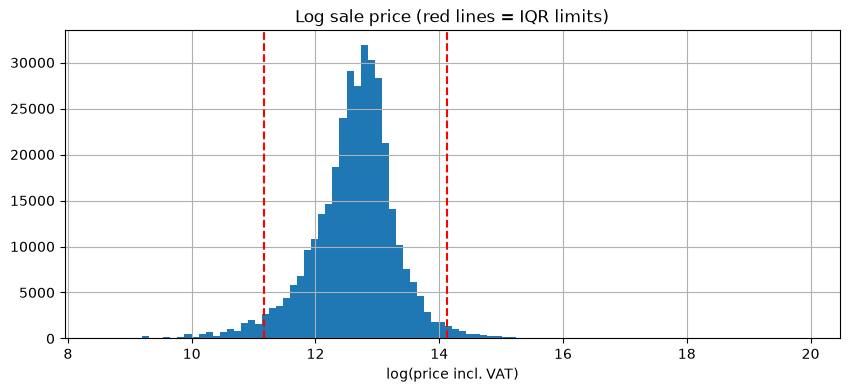

In [11]:
# Log price distribution with the flag limits

plt.figure(figsize=(10, 4))
ppr['log_price'].hist(bins=100)
plt.axvline(lower, color='red', linestyle='--')
plt.axvline(upper, color='red', linestyle='--')
plt.title('Log sale price (red lines = IQR limits)')
plt.xlabel('log(price incl. VAT)')
plt.show()

In [12]:
# Eircode: the full code points at one exact home, so it is not kept.
# The first 3 characters (routing key, e.g. 'D03') are an area code, which
# could be a finer location than county if needed later. 28% are missing.

ppr['eircode_routing_key'] = ppr['eircode'].str[:3]

print('Missing routing key:', round(ppr['eircode_routing_key'].isnull().mean() * 100, 1), '%')
print(ppr['eircode_routing_key'].nunique(), 'routing keys')

Missing routing key: 28.3 %
311 routing keys


In [13]:
# Choosing the columns for the clean table.
# Left out on purpose:
#   eircode               -> identifies one home (routing key kept instead)
#   property_size         -> 100% empty since 2021
#   property_description  -> replaced by property_type
# The address is kept only to spot repeat sales of the same home; it is not
# a model input.

keep = ['sale_id', 'sale_date', 'year', 'quarter', 'county', 'county_id',
        'address', 'eircode_routing_key',
        'property_type', 'vat_exclusive',
        'price_recorded', 'price_incl_vat', 'log_price',
        'not_full_market_price', 'is_extreme_price']

ppr_clean = ppr[keep]

print(ppr_clean.shape)
ppr_clean.head()

(352379, 15)


,sale_id,sale_date,year,quarter,county,county_id,address,eircode_routing_key,property_type,vat_exclusive,price_recorded,price_incl_vat,log_price,not_full_market_price,is_extreme_price
0,1,2021-01-01,2021,2021Q1,Dublin,6,"APT 15, SANDON COVE, CASTLE AVE DUBLIN 3",D03,Second-Hand,0,295000.0,295000.0000,12.594731,0,0
1,2,2021-01-01,2021,2021Q1,Dublin,6,"APT 32, DANES COURT, CLONTARF RD DUBLIN 3",D03,Second-Hand,0,310000.0,310000.0000,12.644328,0,0
2,3,2021-01-03,2021,2021Q1,Dublin,6,"16 BURLEIGH COURT, BURLINGTON ROAD, DUBLIN 4",NaN,Second-Hand,0,450000.0,450000.0000,13.017003,0,0
3,4,2021-01-04,2021,2021Q1,Sligo,21,"1 CASTLEGAL CROSS, CLIFFONEY, CO. SLIGO",NaN,Second-Hand,0,148000.0,148000.0000,11.904968,0,0
4,5,2021-01-04,2021,2021Q1,Cork,4,"1 PLAZA VIEW, FAIR GREEN, MALLOW",NaN,New,1,158590.3,179999.9905,12.100712,0,0


In [14]:
# Missing values left (% per column)

missing = (ppr_clean.isnull().mean() * 100).round(1)
missing[missing > 0]

eircode_routing_key    28.3
dtype: float64

In [15]:
ppr_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 352379 entries, 0 to 352378
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   sale_id                352379 non-null  int64         
 1   sale_date              352379 non-null  datetime64[us]
 2   year                   352379 non-null  int64         
 3   quarter                352379 non-null  str           
 4   county                 352379 non-null  str           
 5   county_id              352379 non-null  int64         
 6   address                352379 non-null  str           
 7   eircode_routing_key    252488 non-null  str           
 8   property_type          352379 non-null  str           
 9   vat_exclusive          352379 non-null  int64         
 10  price_recorded         352379 non-null  float64       
 11  price_incl_vat         352379 non-null  float64       
 12  log_price              352379 non-null  float64       


In [16]:
# Saving the clean PPR table.

save_folder = clean + r'\ppr'
os.makedirs(save_folder, exist_ok=True)

ppr_clean.to_csv(save_folder + r'\ppr_clean.csv', index=False)
print('Saved', ppr_clean.shape, 'to', save_folder + r'\ppr_clean.csv')

Saved (352379, 15) to C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project\dataSet\clean_dataset\ppr\ppr_clean.csv
